# Statistical Analytic Methods
#### Prof. KKIM, Yonsei University
### LEC10. Correlation and Comparison

### Correlation

#### Practice

Pearson correlation coefficient: 0.8014679320174143
R-squared: 0.6423508460522707
p-value: 9.001430312274863e-90


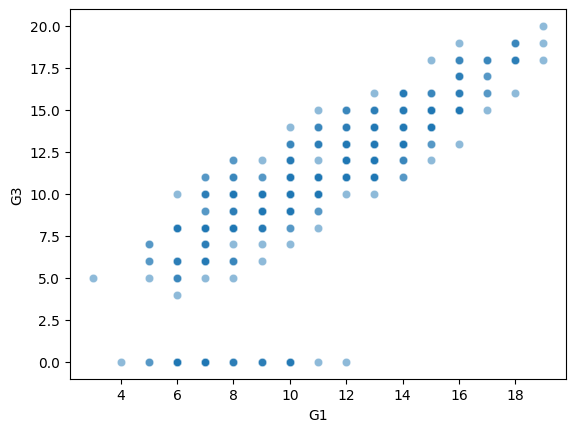

In [ ]:
# Write a short paragraph interpreting the relationship between G1 and G3.
# Scatter plot, Pearson correlation coefficient, R-squared, p-value, Interpretation
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

df = pd.read_csv("/content/drive/MyDrive/[YU]/[Lecture]/[SAM]/01_SAM_Practice/SAM_LEC10/student-mat.csv", sep=";")

sns.scatterplot(data=df, x="G1", y="G3", alpha=0.5)

r, p_value = pearsonr(df["G1"], df["G3"])

r_squared = r ** 2

print("Pearson correlation coefficient:", r)
print("R-squared:", r_squared)
print("p-value:", p_value)

The relationship between G1 and G3 is positive and strong. The Pearson correlation coefficient is approximately 0.801, which means that students with higher first-period grades tend to have higher final grades. The coefficient of determination is approximately 0.642, meaning that about 64.2% of the variation in final grades can be statistically explained by first-period grades. The p-value is smaller than 0.05, so the correlation is statistically significant. However, this relationship should not be interpreted as causal because correlation does not imply causation.

In [ ]:
print(df['G1'].corr(df['G3']))
print(df['G1'].corr(df['G3'], method='pearson'))

0.8014679320174145
0.8014679320174145


In [ ]:
pearsonr(df["G1"], df["G3"])

PearsonRResult(statistic=np.float64(0.8014679320174143), pvalue=np.float64(9.001430312274863e-90))

Correlation coefficient: 0.034247316150069325
R-squared: 0.0011728786634827991
p-value: 0.49733179554352747


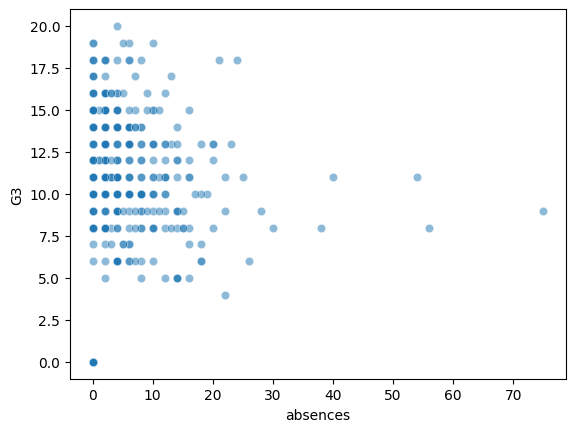

In [ ]:
# Choose another pair of numerical variables from the dataset and conduct your own correlation analysis.
# Scatter plot,  Pearson correlation coefficient, R-squared, p-value, Interpretation
x = "absences"
y = "G3"

sns.scatterplot(data=df, x=x, y=y, alpha=0.5)

r, p_value = pearsonr(df[x], df[y])
r_squared = r ** 2

print("Correlation coefficient:", r)
print("R-squared:", r_squared)
print("p-value:", p_value)

Absences and final grade have a negative correlation. This means that students with more absences tend to have lower final grades. However, this relationship is not necessarily causal because other factors may affect both absences and academic performance.

### t-test

#### Practice

In [ ]:
import pandas as pd
from scipy import stats

df = pd.read_csv("/content/drive/MyDrive/[YU]/[Lecture]/[SAM]/01_SAM_Practice/SAM_LEC10/student_eda_ttest_anova_practice.csv")
df.head()

,student_id,gender,class_type,major,study_hours,attendance_rate,sleep_hours,quiz1,quiz2,quiz3,final_score,satisfaction
0,1,Female,Offline,Sociology,5.4,86.0,6.4,82.0,77.0,100.0,94.0,3.9
1,2,Male,Offline,Sociology,4.9,84.0,4.9,81.0,89.0,93.0,86.0,4.6
2,3,Male,Offline,Engineering,7.5,85.0,7.1,80.0,84.0,98.0,89.0,3.1
3,4,Male,Online,Sociology,5.7,69.0,7.4,60.0,65.0,83.0,77.0,4.2
4,5,Female,Online,Sociology,5.9,71.0,6.2,84.0,91.0,93.0,89.0,3.0


In [ ]:
# What are the average final score of offline and online students?
df.groupby('class_type')['final_score'].mean()

,final_score
class_type,
Offline,86.924812
Online,85.314815


In [ ]:
# Do online and offline students have different average final scores?
from scipy.stats import ttest_ind

online = df[df['class_type'] == 'Online']['final_score']
offline = df[df['class_type'] == 'Offline']['final_score']

print(ttest_ind(online, offline, equal_var=True, nan_policy='omit')) # Student's t-test
print(ttest_ind(online, offline, equal_var=False, nan_policy='omit')) # Welch's t-test

TtestResult(statistic=np.float64(-1.2917451168303709), pvalue=np.float64(0.19769318550503281), df=np.float64(239.0))
TtestResult(statistic=np.float64(-1.2971351707646883), pvalue=np.float64(0.1958713632880409), df=np.float64(232.32076919251853))


In [ ]:
from scipy.stats import levene
stat, p = levene(online,offline,center='median',nan_policy='omit')
print("Levene's test p-value:", p)
# Levene's test examines whether population variances differ,
# while Welch's t-test compares group means without assuming equal variances.

Levene's test p-value: 0.7268840939197836


In [ ]:
levene(online,offline,center='median',nan_policy='omit')

LeveneResult(statistic=np.float64(0.12227862058314742), pvalue=np.float64(0.7268840939197836))

In [ ]:
# What are the average final score of hard-working and not hard-working students?
# (Hard-working students: those study more than the average study hours)
import numpy as np

mean_study_hours = df["study_hours"].mean()
print(mean_study_hours)

df["work_group"] = np.where(
    df["study_hours"] >= mean_study_hours,
    "Hard-working",
    "Not hard-working"
)
df[["student_id", "study_hours", "work_group", "final_score"]].head()

5.239240506329114


,student_id,study_hours,work_group,final_score
0,1,5.4,Hard-working,94.0
1,2,4.9,Not hard-working,86.0
2,3,7.5,Hard-working,89.0
3,4,5.7,Hard-working,77.0
4,5,5.9,Hard-working,89.0


In [ ]:
df.groupby("work_group")["final_score"].agg(["mean", "std", "count"])

,mean,std,count
work_group,,,
Hard-working,90.661017,7.109907,118
Not hard-working,81.926829,9.824001,123


<Axes: xlabel='work_group', ylabel='final_score'>

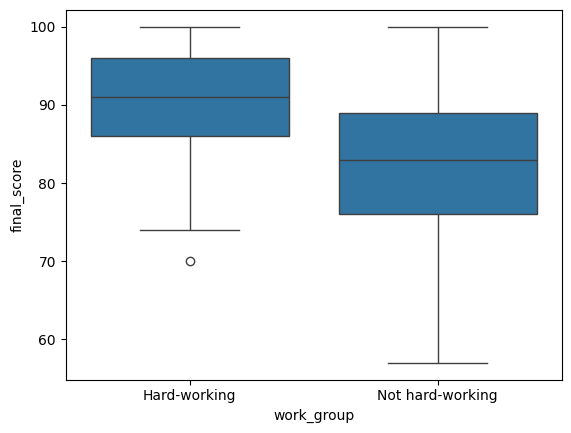

In [ ]:
# Visualize the differences
sns.boxplot(x="work_group", y="final_score", data=df)

In [ ]:
# Do they have different average final scores?
hardworking = df[df["work_group"] == "Hard-working"]["final_score"]
not_hardworking = df[df["work_group"] == "Not hard-working"]["final_score"]

ttest_ind(hardworking, not_hardworking, equal_var=False)

TtestResult(statistic=np.float64(7.930219393434636), pvalue=np.float64(1.054787034873322e-13), df=np.float64(222.44340109199808))

### ANOVA

In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/[YU]/[Lecture]/[SAM]/01_SAM_Practice/SAM_LEC10/student_eda_ttest_anova_practice.csv")
df.groupby('major')['final_score'].mean()

,final_score
major,
Business,86.634615
Economics,85.918919
Engineering,87.984375
Sociology,83.941176


In [ ]:
from scipy.stats import f_oneway

econ = df[df['major'] == 'Economics']['final_score']
eng = df[df['major'] == 'Engineering']['final_score']
soc = df[df['major'] == 'Sociology']['final_score']
bus = df[df['major'] == 'Business']['final_score']

f_oneway(econ, eng, soc, bus)

F_onewayResult(statistic=np.float64(1.7379416423246024), pvalue=np.float64(0.15989083266513854))

#### Practice

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

df = pd.read_csv("/content/drive/MyDrive/[YU]/[Lecture]/[SAM]/01_SAM_Practice/SAM_LEC10/student-mat.csv", sep=";")
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
# P1. Do average final grades differ across different levels of weekly study time?
# What are the average final grades for each study-time group?
df.groupby("studytime")["G3"].agg(["count", "mean", "std"])

,count,mean,std
studytime,,,
1,105,10.047619,4.956311
2,198,10.171717,4.217537
3,65,11.400000,4.639504
4,27,11.259259,5.281263


<Axes: xlabel='studytime', ylabel='G3'>

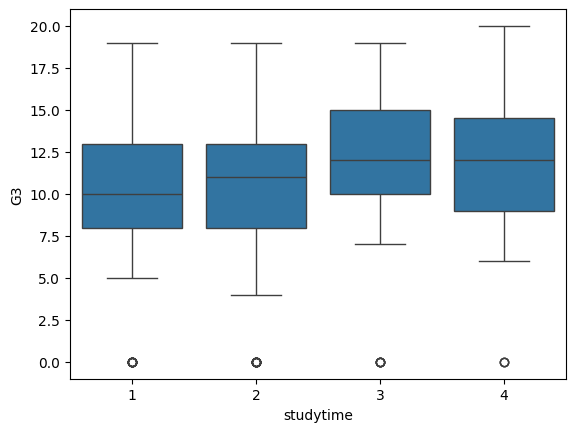

In [ ]:
sns.boxplot(data=df, x="studytime", y="G3")

In [ ]:
# P1. Do average final grades differ across different levels of weekly study time?
# Is the difference statistically significant?
data_studytime = df[["G3", "studytime"]].dropna()
model_studytime = ols("G3 ~ C(studytime)", data=data_studytime).fit()
anova_studytime = sm.stats.anova_lm(model_studytime)
anova_studytime

,df,sum_sq,mean_sq,F,PR(>F)
C(studytime),3.0,108.200155,36.066718,1.727835,0.160723
Residual,391.0,8161.708706,20.873935,NaN,NaN


In [ ]:
# P1. Do average final grades differ across different levels of weekly study time?
# How large is the effect?
ss_between = anova_studytime.loc["C(studytime)", "sum_sq"]
ss_within = anova_studytime.loc["Residual", "sum_sq"]
ss_total = ss_between + ss_within
eta_squared = ss_between / ss_total

eta_squared

np.float64(0.013083596986684315)

In [ ]:
# P1. Do average final grades differ across different levels of weekly study time?
# Which specific groups are significantly different?
tukey_studytime = pairwise_tukeyhsd(
    endog=data_studytime["G3"],
    groups=data_studytime["studytime"],
    alpha=0.05)
print(tukey_studytime)

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     1      2   0.1241  0.996  -1.299 1.5472  False
     1      3   1.3524 0.2403 -0.5081 3.2128  False
     1      4   1.2116 0.6088  -1.332 3.7553  False
     2      3   1.2283  0.238 -0.4568 2.9134  False
     2      4   1.0875 0.6523 -1.3308 3.5059  False
     3      4  -0.1407 0.9991 -2.8397 2.5582  False
---------------------------------------------------


In [ ]:
# P2. Do students’ final grades differ by mother’s education level?
# What are the average final grades for each mother’s education level?
df.groupby("Medu")["G3"].agg(["count", "mean", "std"])

,count,mean,std
Medu,,,
0,3,13.000000,3.464102
1,59,8.677966,4.364594
2,103,9.728155,4.636163
3,99,10.303030,4.623486
4,131,11.763359,4.267646


<Axes: xlabel='Medu', ylabel='G3'>

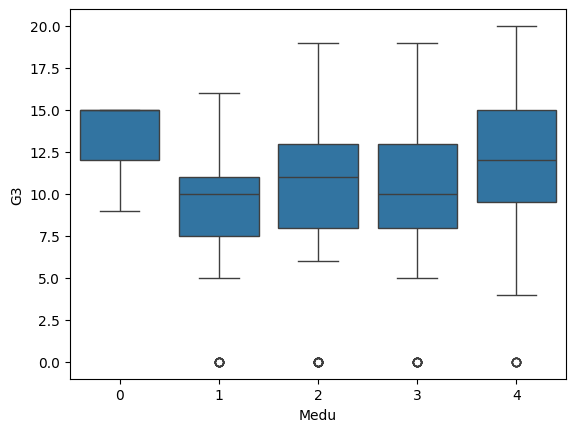

In [ ]:
sns.boxplot(data=df, x="Medu", y="G3")

In [ ]:
# P2. Do students’ final grades differ by mother’s education level?
# Is the difference statistically significant?
data_medu = df[["G3", "Medu"]].dropna()
model_medu = ols("G3 ~ C(Medu)", data=data_medu).fit()
anova_medu = sm.stats.anova_lm(model_medu, typ=2)
anova_medu

,sum_sq,df,F,PR(>F)
C(Medu),486.065942,4.0,6.088436,0.000092
Residual,7783.842918,390.0,NaN,NaN


In [ ]:
# P2. Do students’ final grades differ by mother’s education level?
# How large is the effect?
ss_between = anova_medu.loc["C(Medu)", "sum_sq"]
ss_within = anova_medu.loc["Residual", "sum_sq"]
ss_total = ss_between + ss_within
eta_squared = ss_between / ss_total
eta_squared

np.float64(0.05877524776271708)

In [ ]:
# P2. Do students’ final grades differ by mother’s education level?
# Which specific groups are significantly different?
tukey_medu = pairwise_tukeyhsd(
    endog=data_medu["G3"],
    groups=data_medu["Medu"],
    alpha=0.05)
print(tukey_medu)

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     0      1   -4.322 0.4761 -11.5683 2.9243  False
     0      2  -3.2718 0.7217 -10.4429 3.8992  False
     0      3   -2.697 0.8413  -9.8721 4.4782  False
     0      4  -1.2366 0.9896  -8.3859 5.9127  False
     1      2   1.0502 0.6023  -0.9488 3.0492  False
     1      3   1.6251 0.1775  -0.3886 3.6388  False
     1      4   3.0854 0.0001   1.1657  5.005   True
     2      3   0.5749 0.8914  -1.1484 2.2981  False
     2      4   2.0352 0.0054   0.4228 3.6476   True
     3      4   1.4603 0.1034  -0.1702 3.0908  False
----------------------------------------------------


### Chi-square

### Practice

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

df = pd.read_csv("/content/drive/MyDrive/[YU]/[Lecture]/[SAM]/01_SAM_Practice/SAM_LEC10/student-mat.csv", sep=";")
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
# P1. Is internet access associated with students' residential area?
# How many urban and rural students have internet access?
# table = pd.crosstab(df["address"], df["internet"])
table = df.groupby(["address", "internet"]).size().unstack(fill_value=0)
table

internet,no,yes
address,,
R,28,60
U,38,269


In [ ]:
# P1. Is internet access associated with students' residential area?
# Compare the proportion of students with internet access across residential areas.
# prop_table = pd.crosstab(df["address"], df["internet"],normalize="index") * 100
prop_table = table.div(table.sum(axis=1), axis=0) * 100
prop_table

internet,no,yes
address,,
R,31.818182,68.181818
U,12.377850,87.622150


<Axes: xlabel='Residential Area', ylabel='Share'>

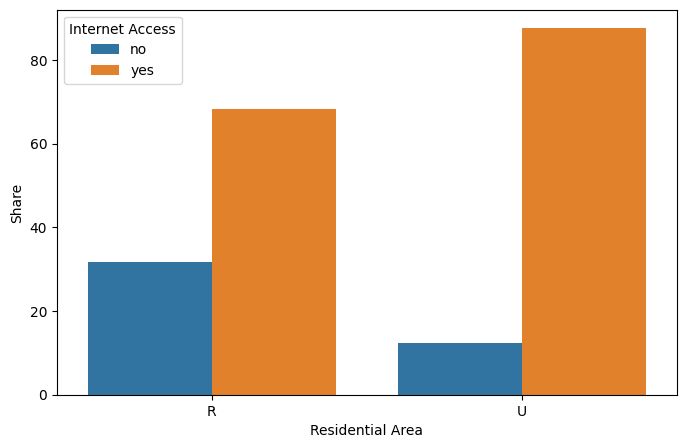

In [ ]:
# P1. Is internet access associated with students' residential area?
# Visualize the relationship.
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plot_data = (
    prop_table
    .rename_axis("Residential Area")
    .reset_index()
    .melt(
        id_vars="Residential Area",
        var_name="Internet Access",
        value_name="Share"
    )
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=plot_data,
    x="Residential Area",
    y="Share",
    hue="Internet Access")

# prop_table.plot(kind="bar", stacked=True)
# plt.xlabel("Residential Area")
# plt.ylabel("Percentage")
# plt.title("Internet Access by Residential Area")
# plt.legend(title="Internet Access")
# plt.show()

In [ ]:
# P1. Is internet access associated with students' residential area?
# Is the relationship statistically significant?
chi2, p_value, dof, expected = chi2_contingency(table)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)
print("Degrees of freedom:", dof)

expected_table = pd.DataFrame(
    expected,index=table.index,columns=table.columns)
expected_table

Chi-square statistic: 17.202541580860636
p-value: 3.3598654758469596e-05
Degrees of freedom: 1


internet,no,yes
address,,
R,14.703797,73.296203
U,51.296203,255.703797


In [ ]:
# Observed: what we actually see in the data
# Expected: what we would expect if the two variables were independent

In [ ]:
# P1. Is internet access associated with students' residential area?
# How strong is the association?
n = table.to_numpy().sum()
rows, cols = table.shape

cramers_v = np.sqrt(chi2 / (n * min(rows - 1, cols - 1)))
print("Cramer's V:", cramers_v)

Cramer's V: 0.20868813617308007


In [ ]:
# P2. Does the reason for choosing the school differ between urban and rural students?
# What is the distribution of school-choice reasons for urban and rural students?
# table_reason = pd.crosstab(df["address"],df["reason"])
table_reason = df.groupby(["address", "reason"]).size().unstack(fill_value=0)
table_reason

reason,course,home,other,reputation
address,,,,
R,36,13,10,29
U,109,96,26,76


In [ ]:
# P2. Does the reason for choosing the school differ between urban and rural students?
# Compare the proportions across the two residential areas.
# prop_reason = pd.crosstab(df["address"],df["reason"],normalize="index") * 100
prop_reason = table_reason.div(table_reason.sum(axis=1), axis=0) * 100
prop_reason

reason,course,home,other,reputation
address,,,,
R,40.909091,14.772727,11.363636,32.954545
U,35.504886,31.270358,8.469055,24.755700


<Axes: xlabel='Residential Area', ylabel='Percentage'>

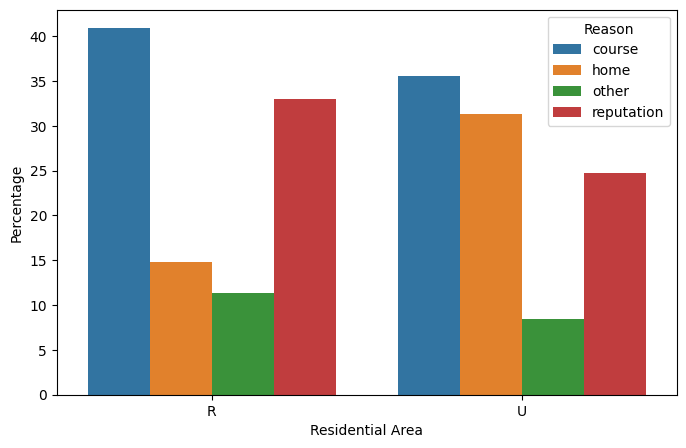

In [ ]:
# P2. Does the reason for choosing the school differ between urban and rural students?
# Visualize the relationship.
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plot_reason = (
    prop_reason
    .rename_axis("Residential Area")
    .reset_index()
    .melt(
        id_vars="Residential Area",
        var_name="Reason",
        value_name="Percentage"
    )
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=plot_reason,
    x="Residential Area",
    y="Percentage",
    hue="Reason"
)

# prop_reason.plot(kind="bar", stacked=True)
# plt.xlabel("Residential Area")
# plt.ylabel("Percentage")
# plt.title("Reasons for Choosing School by Residential Area")
# plt.legend(title="Reason")
# plt.show()

In [ ]:
# P2. Does the reason for choosing the school differ between urban and rural students?
# Is the relationship statistically significant?
chi2, p_value, dof, expected = chi2_contingency(table_reason)

print("Chi-square statistic:", chi2)
print("p-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 9.648346939399616
p-value: 0.021804456830089435
Degrees of freedom: 3


In [ ]:
# P2. Does the reason for choosing the school differ between urban and rural students?
# How strong is the association?
n = table_reason.to_numpy().sum()
rows, cols = table_reason.shape

cramers_v = np.sqrt(chi2 / (n * min(rows - 1, cols - 1)))
print("Cramer's V:", cramers_v)

Cramer's V: 0.15628881848452936
